# Stage 7 : Final test-set evaluation

**This is the only time the test set is used.** Every model is evaluated exactly as it was frozen on validation:
same weights, same settings, same prompts. Nothing here may be changed after looking at the results.

| Part | What | Runtime |
|---|---|---|
| 1 | Majority class, Random Forest, XGBoost (3 seeds, best Stage 2 settings) + **end-to-end** classical latency | CPU/GPU |
| 2 | ResNet-18 (initial and tuned), EfficientNet-B2, **ViT (final ANN)** — 3 seeds each | **T4 GPU** |
| 3 | Calibration and app settings on the test set (temperature, low-certainty threshold, OOD check) | GPU/CPU |
| 4 | **TerraMind** (3 seeds) — needs `terratorch` (install → restart, like Stage 6) | **T4 GPU** |
| 5 | **Gemini few-shot** on all 668 test images (≈ 1–1.5 h, saved after every image) | any |
| 6 | Final comparison table + figures | any |
| 7 | Submission helpers: dataset download script, small data sample, requirements | any |

Each part saves its results in `outputs/stage7/`, so parts can be run in any order or in different sessions.


## 0. Setup

In [ ]:
import subprocess, sys, os
if os.environ.get("FN_QUICK") != "1":
    subprocess.run([sys.executable, "-m", "pip", "-q", "install", "timm", "xgboost", "scikit-image", "google-genai"], check=False)

In [ ]:
import os, json, time, random, hashlib, zipfile, io, math, base64, re, warnings, pickle
from pathlib import Path
import numpy as np, pandas as pd

SEED = 42; SEEDS = [42, 43, 44]
QUICK = os.environ.get("FN_QUICK") == "1"                 # offline testing only — leave unset
IN_COLAB = "google.colab" in sys.modules
if os.environ.get("FORESTNET_BASE"):
    BASE = Path(os.environ["FORESTNET_BASE"])
elif IN_COLAB:
    from google.colab import drive
    drive.mount("/content/drive")
    BASE = Path("/content/drive/MyDrive/forestnet_project")
else:
    BASE = Path("./forestnet_project")
OUT = BASE / "outputs"; OUT7 = OUT / "stage7"; OUT7.mkdir(parents=True, exist_ok=True); CACHE = BASE / "cache"

import torch, torch.nn as nn, torch.nn.functional as F
import matplotlib.pyplot as plt
from PIL import Image
from sklearn.metrics import f1_score, recall_score, accuracy_score, confusion_matrix, ConfusionMatrixDisplay
warnings.filterwarnings("ignore", message="Unpickling a shapely")
pd.set_option("display.width", 220); pd.set_option("display.max_columns", 30); pd.set_option("display.max_colwidth", 70)
DEV = "cuda" if torch.cuda.is_available() else "cpu"
print("device:", DEV, torch.cuda.get_device_name(0) if DEV == "cuda" else "")

def sha256(path, chunk=1 << 20):
    h = hashlib.sha256()
    with open(path, "rb") as f:
        for b in iter(lambda: f.read(chunk), b""):
            h.update(b)
    return h.hexdigest()

meta = json.load(open(OUT / "dataset_meta.json"))
assert sha256(OUT / "split_manifest.csv") == meta["manifest_sha256"], "Split changed!"
man = pd.read_csv(OUT / "split_manifest.csv").sort_values("example_path").reset_index(drop=True)
CLASSES = sorted(man["merged_label"].unique()); CLS2ID = {c: i for i, c in enumerate(CLASSES)}
man["y"] = man["merged_label"].map(CLS2ID)
P_ID, S_ID, O_ID, G_ID = (CLS2ID["Plantation"], CLS2ID["Smallholder agriculture"], CLS2ID["Other"], CLS2ID["Grassland shrubland"])
TR_IDX = np.where(man.split == "train")[0]; VA_IDX = np.where(man.split == "val")[0]; TE_IDX = np.where(man.split == "test")[0]
Y_TE = man.y.values[TE_IDX]
print("Test events:", len(TE_IDX), dict(zip(*np.unique(man.merged_label.values[TE_IDX], return_counts=True))))

def evaluate(y_true, y_pred):
    y_true, y_pred = np.asarray(y_true), np.asarray(y_pred)
    rec = recall_score(y_true, y_pred, labels=range(len(CLASSES)), average=None, zero_division=0)
    return {"macro_f1": f1_score(y_true, y_pred, labels=range(len(CLASSES)), average="macro", zero_division=0),
            "accuracy": accuracy_score(y_true, y_pred), "recall_plantation": rec[P_ID], "recall_smallholder": rec[S_ID],
            "recall_other": rec[O_ID], "recall_grassland": rec[G_ID],
            "rate_P_to_S": float((y_pred[y_true == P_ID] == S_ID).mean()),
            "rate_O_to_SG": float(np.isin(y_pred[y_true == O_ID], [S_ID, G_ID]).mean())}

def save_result(name, per_seed, extra=None):
    """per_seed: list of metric dicts (one per seed). Saved once; never overwritten (test set used once)."""
    f = OUT7 / f"{name}.json"
    if f.exists():
        print(f"{name}: already evaluated on test — kept as is."); return json.load(open(f))
    res = {"model": name, "per_seed": per_seed, "extra": extra or {}, "created": time.strftime("%Y-%m-%d %H:%M")}
    json.dump(res, open(f, "w"), indent=2, default=float); print(f"{name}: saved (macro-F1 {np.mean([m['macro_f1'] for m in per_seed]):.3f})")
    return res

ZF = zipfile.ZipFile(BASE / "data" / "ForestNetDataset.zip")
PREFIX = next(n for n in ZF.namelist() if n.endswith("train.csv"))[:-len("train.csv")]
def read_png(example_path, name="composite.png"):
    return np.asarray(Image.open(io.BytesIO(ZF.read(f"{PREFIX}{example_path}/images/visible/{name}"))).convert("RGB"))

Mounted at /content/drive
device: cpu 
Test events: 668 {'Grassland shrubland': np.int64(77), 'Other': np.int64(106), 'Plantation': np.int64(269), 'Smallholder agriculture': np.int64(216)}


## Part 1 : Trivial benchmark and classical baseline
RF and XGBoost are retrained with the **best Stage 2 settings** and seeds 42, 43, 44 on the **same cached features**
(training data only), then predict the test set. This reproduces exactly the three validation runs of Stage 2.

In [ ]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.utils.class_weight import compute_sample_weight
import xgboost
from xgboost import XGBClassifier

maj = int(np.bincount(man.y.values[TR_IDX]).argmax())
save_result("majority_class", [evaluate(Y_TE, np.full(len(TE_IDX), maj))])

s2 = OUT / "stage2"
s2res = json.load(open(s2 / "stage2_results.json"))
feats = pd.read_csv(next(s2.glob("features_nir*_crop*.csv")))
FEATURES = s2res["features"]
data = man.merge(feats, on="example_path", how="left")
X_tr, y_tr = data.loc[TR_IDX, FEATURES].values, data.y.values[TR_IDX]
X_te = data.loc[TE_IDX, FEATURES].values
assert not np.isnan(X_te).any(), "Missing test features"

def fit_classical(kind, s):
    p = s2res["best_params"][kind]
    if kind == "RF":
        m = RandomForestClassifier(**p, class_weight="balanced", random_state=s, n_jobs=-1)
        t0 = time.time(); m.fit(X_tr, y_tr)
    else:
        m = XGBClassifier(**p, objective="multi:softprob", num_class=len(CLASSES), tree_method="hist",
                          eval_metric="mlogloss", random_state=s, n_jobs=-1)
        t0 = time.time(); m.fit(X_tr, y_tr, sample_weight=compute_sample_weight("balanced", y_tr))
    return m, time.time() - t0

classical_models = {}
for kind, name in [("RF", "random_forest"), ("XGB", "xgboost")]:
    per_seed, times = [], []
    for s in SEEDS:
        m, ts = fit_classical(kind, s); times.append(ts)
        per_seed.append(evaluate(Y_TE, m.predict(X_te)))
        if s == SEED:
            classical_models[kind] = m
    save_result(name, per_seed, {"train_s": float(np.mean(times)), "params": s2res["best_params"][kind]})

majority_class: saved (macro-F1 0.144)
random_forest: saved (macro-F1 0.616)
xgboost: saved (macro-F1 0.615)


In [ ]:
# End-to-end latency of the classical baseline: read PNG + infrared file -> 68 features -> prediction (CPU, 1 image)
from skimage.feature import graycomatrix, graycoprops
NIR_CH, CROP = s2res["nir_channel"], s2res["crop"]
def centre(a, size=CROP):
    h, w = a.shape[:2]; t, l = (h - size) // 2, (w - size) // 2; return a[t:t + size, l:l + size]
def stats(x, name):
    x = x.ravel(); q10, q50, q90 = np.percentile(x, [10, 50, 90])
    return {f"{name}_mean": x.mean(), f"{name}_std": x.std(), f"{name}_p10": q10, f"{name}_p50": q50, f"{name}_p90": q90}
def glcm_feats(gray, prefix):
    lo, hi = np.percentile(gray, [2, 98]); q = np.clip((gray - lo) / (hi - lo + 1e-6), 0, 1)
    q = np.minimum((q * 32).astype(np.uint8), 31)
    g = graycomatrix(q, distances=[1, 3], angles=[0, np.pi / 4, np.pi / 2, 3 * np.pi / 4], levels=32, symmetric=True, normed=True)
    out = {}
    for prop in ["contrast", "dissimilarity", "homogeneity", "energy", "correlation", "ASM"]:
        v = graycoprops(g, prop)
        for di, d in enumerate([1, 3]):
            out[f"{prefix}_glcm_{prop}_d{d}"] = v[di].mean()
    return out
def region_feats(vis, ir, prefix):
    f = {}; v = vis.astype(np.float32) / 255.0
    for ci, cn in enumerate("RGB"):
        f.update(stats(v[..., ci], f"{prefix}_{cn}"))
    red = vis[..., 0].astype(np.float32); nir = ir[..., NIR_CH].astype(np.float32); nd = (nir - red) / (nir + red + 1e-6)
    f.update(stats(nd, f"{prefix}_ndvi")); f[f"{prefix}_ndvi_gt06"] = float((nd > 0.6).mean()); f[f"{prefix}_ndvi_lt02"] = float((nd < 0.2).mean())
    gray = 0.299 * v[..., 0] + 0.587 * v[..., 1] + 0.114 * v[..., 2]; f.update(glcm_feats(gray, prefix)); return f
def classical_end_to_end(p, model):
    vis = read_png(p); ir = np.load(io.BytesIO(ZF.read(f"{PREFIX}{p}/images/infrared/composite.npy")))
    f = {**region_feats(vis, ir, "w"), **region_feats(centre(vis), centre(ir), "c")}
    return model.predict(np.array([[f[k] for k in FEATURES]]))[0]

lat_cls = {}
try:
    for kind in ("RF", "XGB"):
        ts = []
        for p in man.example_path.values[VA_IDX][:12]:            # validation images are enough for timing
            t0 = time.perf_counter(); classical_end_to_end(p, classical_models[kind]); ts.append((time.perf_counter() - t0) * 1000)
        lat_cls[kind] = float(np.median(ts[2:]))
    print("Classical end-to-end latency (CPU, ms):", {k: round(v) for k, v in lat_cls.items()})
except Exception as e:
    print("Classical latency skipped:", repr(e))
json.dump(lat_cls, open(OUT7 / "latency_classical.json", "w"))

Classical end-to-end latency (CPU, ms): {'RF': 2097, 'XGB': 22}


## Part 2 : Neural models (ResNet-18 initial / tuned, EfficientNet-B2, ViT) on the test set
The saved best weights of each final run (3 seeds) are loaded and applied to the 668 test composites (224 px cache,
training-set normalisation, no augmentation) - exactly as on validation.

In [ ]:
import timm
COMP = np.load(CACHE / "comp_full.npy")
MEAN = torch.tensor(meta["train_rgb_norm"]["mean"]).view(1, 3, 1, 1); STD = torch.tensor(meta["train_rgb_norm"]["std"]).view(1, 3, 1, 1)
TIMM = {"resnet18": "resnet18.tv_in1k", "effnet_b2": "efficientnet_b2.ra_in1k", "vit_small": "vit_small_patch16_224.augreg_in21k_ft_in1k"}

class ViTClassifier(nn.Module):
    def __init__(self, depth=12, n_frozen=3, hidden=256, drop=0.2):
        super().__init__()
        self.backbone = timm.create_model(TIMM["vit_small"], pretrained=False, num_classes=0)
        self.backbone.blocks = self.backbone.blocks[:depth]; d = self.backbone.num_features
        self.head = nn.Sequential(nn.LayerNorm(2 * d), nn.Dropout(drop), nn.Linear(2 * d, hidden), nn.GELU(), nn.Dropout(drop), nn.Linear(hidden, len(CLASSES)))
    def forward(self, x):
        t = self.backbone.forward_features(x); return self.head(torch.cat([t[:, 0], t[:, 1:].mean(1)], dim=1))

def build(cfg):
    if cfg["arch"] == "vit_small":
        return ViTClassifier(cfg["depth"], cfg["n_frozen"], cfg["hidden"], cfg["drop"])
    return timm.create_model(TIMM[cfg["arch"]], pretrained=False, num_classes=len(CLASSES))

@torch.no_grad()
def logits_on(model, idx, bs=64):
    model.eval(); out = []
    for b in range(0, len(idx), bs):
        x = torch.from_numpy(COMP[idx[b:b + bs]]).permute(0, 3, 1, 2).float() / 255.0
        out.append(model(((x - MEAN) / STD).to(DEV)).float().cpu())
    return torch.cat(out)

RUNS3 = OUT / "stage3" / "runs"; lat3 = pd.read_csv(OUT / "stage3" / "latency.csv", index_col=0) if (OUT / "stage3" / "latency.csv").exists() else None
TEST_LOGITS = {}
for name, prefix in [("resnet18_initial", "S3-R18-INIT"), ("resnet18_tuned", "S3-R18-FINAL"),
                     ("efficientnet_b2", "S3-EFB2-FINAL"), ("vit_small_final", "S3-VIT-FINAL")]:
    per_seed, trs = [], []
    for s in SEEDS:
        rdir = RUNS3 / f"{prefix}-s{s}"
        r = json.load(open(rdir / "result.json")); m = build(r["cfg"])
        assert r["cfg"].get("view", "full") == "full", f"{rdir.name} used view {r['cfg'].get('view')} — tell Claude"
        m.load_state_dict(torch.load(rdir / "best.pt", map_location="cpu")); m.to(DEV)
        lg = logits_on(m, TE_IDX); TEST_LOGITS[(name, s)] = lg
        per_seed.append(evaluate(Y_TE, lg.argmax(1).numpy())); trs.append(r["train_s"])
        np.save(OUT7 / f"test_pred_{name}_s{s}.npy", lg.argmax(1).numpy())
        del m; torch.cuda.empty_cache() if DEV == "cuda" else None
    save_result(name, per_seed, {"train_s": float(np.mean(trs))})

resnet18_initial: saved (macro-F1 0.658)
resnet18_tuned: saved (macro-F1 0.670)
efficientnet_b2: saved (macro-F1 0.671)
vit_small_final: saved (macro-F1 0.696)


## Part 3 : Calibration and app settings on the test set
The app uses the ViT run chosen in Stage 4/5 with the temperature T and threshold fixed on validation. Here we check
them honestly on the test set: calibration error, how many events the 0.60 threshold sends to manual review, and how
often the out-of-distribution check would wrongly withhold a genuine test image.

In [ ]:
cfg_app = json.load(open(BASE / "app" / "config.json"))
s_app = int(cfg_app["model_run_id"].split("-s")[-1]); T = cfg_app["temperature"]; LOW = cfg_app["low_confidence_threshold"]
lg = TEST_LOGITS[("vit_small_final", s_app)]; yt = torch.tensor(Y_TE)

def ece(p, y, n=10):
    conf, pred = p.max(1); acc = (pred == y).float(); e = 0.0; edges = torch.linspace(0, 1, n + 1)
    for lo, hi in zip(edges[:-1], edges[1:]):
        s = (conf > lo) & (conf <= hi)
        if s.any(): e += s.float().mean() * (acc[s].mean() - conf[s].mean()).abs()
    return float(e)
p_raw, p_cal = F.softmax(lg, 1), F.softmax(lg / T, 1)
conf = p_cal.max(1).values; correct = (p_cal.argmax(1) == yt)
calib_test = {"model": cfg_app["model_run_id"], "temperature": T,
              "ece_raw": ece(p_raw, yt), "ece_calibrated": ece(p_cal, yt),
              "mean_conf_raw": float(p_raw.max(1).values.mean()), "mean_conf_cal": float(conf.mean()),
              "accuracy": float(correct.float().mean()), "share_flagged": float((conf < LOW).float().mean()),
              "acc_flagged": float(correct[conf < LOW].float().mean()) if (conf < LOW).any() else None,
              "acc_not_flagged": float(correct[conf >= LOW].float().mean())}
OOD = cfg_app["ood_ranges"]
def img_stats(img):
    img = img.astype(np.float32); return {"mean_brightness": img.mean(), "contrast": img.std(), "green_ratio": img[..., 1].mean() / (img.mean() + 1e-6)}
flags = [any(not (OOD[k][0] <= v <= OOD[k][1]) for k, v in img_stats(read_png(p)).items()) for p in man.example_path.values[TE_IDX]]
calib_test["ood_false_alarm_test"] = float(np.mean(flags))
json.dump(calib_test, open(OUT7 / "calibration_test.json", "w"), indent=2)
display(pd.Series(calib_test).to_frame("test set"))

,test set
model,S3-VIT-FINAL-s43
temperature,2.141579
ece_raw,0.202377
ece_calibrated,0.083562
mean_conf_raw,0.947886
mean_conf_cal,0.824029
accuracy,0.745509
share_flagged,0.107784
acc_flagged,0.5
acc_not_flagged,0.775168


## Part 4 : TerraMind on the test set (needs `terratorch`)


In [ ]:
!pip -q install "terratorch>=1.2.5" "numpy<2.3" "pandas==2.2.3" "python-dateutil<3"   # <- uncomment if needed, then restart

  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done


In [ ]:
import importlib.util
if importlib.util.find_spec("terratorch") is None:
    print("terratorch not installed in this session — see the note above. Skipping TerraMind for now.")
else:
    from terratorch.registry import BACKBONE_REGISTRY
    class TerraMindClassifier(nn.Module):
        def __init__(self, drop=0.2):
            super().__init__()
            self.backbone = BACKBONE_REGISTRY.build("terramind_v1_base", pretrained=False, modalities=["RGB"])
            self.head = nn.Sequential(nn.LayerNorm(768), nn.Dropout(drop), nn.Linear(768, len(CLASSES)))
        def forward(self, x):
            return self.head(self.backbone(x)[-1].mean(1))
    tm = json.load(open(OUT / "stage6" / "terramind_final.json"))
    per_seed, trs = [], []
    for rid in tm["final_run_ids"]:
        rdir = OUT / "stage6" / "runs" / rid; r = json.load(open(rdir / "result.json"))
        m = TerraMindClassifier(); m.load_state_dict(torch.load(rdir / "best.pt", map_location="cpu")); m.to(DEV)
        pred = logits_on(m, TE_IDX).argmax(1).numpy(); np.save(OUT7 / f"test_pred_terramind_s{r['seed']}.npy", pred)
        per_seed.append(evaluate(Y_TE, pred)); trs.append(r["train_s"])
        del m; torch.cuda.empty_cache() if DEV == "cuda" else None
    save_result("terramind", per_seed, {"train_s": float(np.mean(trs)), "lr": tm["best_lr"]})

terramind: saved (macro-F1 0.678)


## Part 5 : Gemini few-shot on all test images (prompt fixed on validation in Stage 6)
Uses exactly the saved model id, prompt text, few-shot training examples and image preprocessing from Stage 6.

API errors are **not** counted as answers: those images are retried on the next run.

In [ ]:
from getpass import getpass
vp = json.load(open(OUT / "stage6" / "vlm_prompts_final.json"))
G = vp["chosen"].get("gemini")
print("Frozen Gemini settings:", G)
GEMINI_KEY = None
if G:
    try:
        from google.colab import userdata; GEMINI_KEY = userdata.get("GEMINI_API_KEY")
    except Exception:
        pass
    if not GEMINI_KEY:
        GEMINI_KEY = os.environ.get("GEMINI_API_KEY") if QUICK else getpass("Paste your Gemini API key (Enter to skip): ").strip() or None

Frozen Gemini settings: {'model': 'gemini-3.5-flash-lite', 'few_shot': True, 'val_macro_f1': 0.46184640522875814}
Paste your Gemini API key (Enter to skip): ··········


In [ ]:
#was not able to execute due to a api key invalid issue and limist
SLEEP_S = 4.5
if G and GEMINI_KEY:
    from google import genai
    from google.genai import types
    gclient = genai.Client(api_key=GEMINI_KEY)
    def png_bytes(p):
        img = read_png(p); lo, hi = np.percentile(img, [2, 98]); s = np.clip((img.astype(np.float32) - lo) / (hi - lo + 1e-6), 0, 1)
        buf = io.BytesIO(); Image.fromarray((s * 255).astype(np.uint8)).save(buf, "PNG"); return buf.getvalue()
    def call_gemini(q):
        parts = []
        if G["few_shot"]:
            parts.append(vp["few_shot_intro"])
            for c, p in vp["few_shot_examples"]:
                parts += [f"Example - class: {c}", types.Part.from_bytes(data=png_bytes(p), mime_type="image/png")]
            parts.append("Now classify this image. " + vp["ask"])
        else:
            parts.append(vp["zero_shot_prompt"])
        parts.append(types.Part.from_bytes(data=q, mime_type="image/png"))
        r = gclient.models.generate_content(model=G["model"], contents=parts,
                                            config=types.GenerateContentConfig(temperature=0, response_mime_type="application/json"))
        return r.text or ""
    def parse_label(text):
        try:
            lab = str(json.loads(re.search(r"\{.*\}", text, re.S).group(0)).get("label", "")).strip().lower()
        except Exception:
            lab = text.lower()
        for c in CLASSES:
            if lab.startswith(c.lower().split()[0]):
                return c
        return None
    out_csv = OUT7 / "gemini_test_answers.csv"
    done = pd.read_csv(out_csv) if out_csv.exists() else pd.DataFrame(columns=["example_path", "true", "pred", "raw", "latency_ms"])
    rows = done.to_dict("records"); have = set(done.example_path)
    todo = [p for p in man.example_path.values[TE_IDX] if p not in have][: (3 if QUICK else None)]
    print(f"Gemini test: {len(todo)} images to query, {len(have)} already answered")
    for i, p in enumerate(todo):
        q = png_bytes(p)
        for attempt in range(4):
            try:
                t0 = time.perf_counter(); text = call_gemini(q); lat = (time.perf_counter() - t0) * 1000; break
            except Exception as e:
                text, lat = None, None; err = repr(e)[:120]; time.sleep(15 * (attempt + 1))
        if text is None:
            print("  API error (will retry next run):", err); continue          # not saved -> retried later
        rows.append({"example_path": p, "true": man.set_index("example_path").merged_label[p], "pred": parse_label(text),
                     "raw": text[:300], "latency_ms": lat})
        pd.DataFrame(rows).to_csv(out_csv, index=False)
        if (i + 1) % 25 == 0:
            print(f"  {len(rows)}/{len(TE_IDX)} answered")
        time.sleep(SLEEP_S)
    df = pd.read_csv(out_csv)
    print(f"Answered {len(df)}/{len(TE_IDX)} test images.")
    if len(df) == len(TE_IDX) or QUICK:
        y = df.true.map(CLS2ID).values; yp = df.pred.map(CLS2ID).fillna(-1).astype(int).values
        m = evaluate(y, yp); m["invalid_rate"] = float((yp == -1).mean())
        save_result("gemini_fewshot" if G["few_shot"] else "gemini_zeroshot", [m],
                    {"model": G["model"], "few_shot": G["few_shot"], "median_latency_ms": float(df.latency_ms.median()), "n": int(len(df))})
    else:
        print("Not all test images answered yet — run this cell again later to finish.")
else:
    print("Gemini part skipped (no frozen settings or no key).")

Gemini test: 668 images to query, 0 already answered
  API error (will retry next run): ClientError("401 UNAUTHENTICATED. {'error': {'code': 401, 'message': 'API key not valid. Please pass a valid API key.', 
  API error (will retry next run): ClientError("401 UNAUTHENTICATED. {'error': {'code': 401, 'message': 'API key not valid. Please pass a valid API key.', 
  API error (will retry next run): ClientError("401 UNAUTHENTICATED. {'error': {'code': 401, 'message': 'API key not valid. Please pass a valid API key.', 
  API error (will retry next run): ClientError("401 UNAUTHENTICATED. {'error': {'code': 401, 'message': 'API key not valid. Please pass a valid API key.', 


KeyboardInterrupt: 

## Part 6 :Final comparison table (test set)
Mean ± standard deviation over 3 seeds where models were trained with 3 seeds. Latency: end-to-end per image.

In [ ]:
names = [("majority_class", "Majority class (trivial benchmark)"), ("random_forest", "Random Forest"), ("xgboost", "XGBoost"),
         ("resnet18_initial", "ResNet-18 (initial ANN)"), ("resnet18_tuned", "ResNet-18 (tuned)"), ("efficientnet_b2", "EfficientNet-B2"),
         ("vit_small_final", "ViT-Small (final ANN)"), ("terramind", "TerraMind-1.0-base (fine-tuned)"),
         ("gemini_fewshot", "Gemini few-shot (prompted)"), ("gemini_zeroshot", "Gemini zero-shot (prompted)")]
lat_cls = json.load(open(OUT7 / "latency_classical.json")) if (OUT7 / "latency_classical.json").exists() else {}
lat_map = {"random_forest": (None, lat_cls.get("RF")), "xgboost": (None, lat_cls.get("XGB"))}
if lat3 is not None:
    lat_map.update({"resnet18_initial": (lat3.loc["ResNet-18 (initial)", "gpu_ms"], lat3.loc["ResNet-18 (initial)", "cpu_ms"]),
                    "resnet18_tuned": (lat3.loc["ResNet-18 (tuned)", "gpu_ms"], lat3.loc["ResNet-18 (tuned)", "cpu_ms"]),
                    "efficientnet_b2": (lat3.loc["EfficientNet-B2", "gpu_ms"], lat3.loc["EfficientNet-B2", "cpu_ms"]),
                    "vit_small_final": (lat3.loc["ViT-Small (final)", "gpu_ms"], lat3.loc["ViT-Small (final)", "cpu_ms"])})
rows = []
for key, label in names:
    f = OUT7 / f"{key}.json"
    if not f.exists():
        continue
    r = json.load(open(f)); d = pd.DataFrame(r["per_seed"])
    fmt = lambda c: f"{d[c].mean():.3f} ± {d[c].std():.3f}" if len(d) > 1 else f"{d[c].mean():.3f}"
    gpu, cpu = lat_map.get(key, (None, None))
    if key.startswith("gemini"):
        gpu, cpu = None, r["extra"].get("median_latency_ms")
    tr = r["extra"].get("train_s")
    rows.append({"Model": label, "Macro-F1": fmt("macro_f1"), "Accuracy": f"{d.accuracy.mean():.3f}",
                 "Recall P": f"{d.recall_plantation.mean():.2f}", "Recall S": f"{d.recall_smallholder.mean():.2f}",
                 "Recall O": f"{d.recall_other.mean():.2f}", "Recall G": f"{d.recall_grassland.mean():.2f}",
                 "P→S": f"{d.rate_P_to_S.mean():.3f}", "O→S/G": f"{d.rate_O_to_SG.mean():.3f}",
                 "Train (min)": "—" if tr is None else f"{tr / 60:.2f}",
                 "Latency GPU / CPU-or-API (ms)": f"{'—' if gpu is None or pd.isna(gpu) else round(float(gpu), 1)} / {'—' if cpu is None else round(float(cpu))}"})
final = pd.DataFrame(rows); display(final); final.to_csv(OUT7 / "final_test_table.csv", index=False)

,Model,Macro-F1,Accuracy,Recall P,Recall S,Recall O,Recall G,P→S,O→S/G,Train (min),Latency GPU / CPU-or-API (ms)
0,Majority class (trivial benchmark),0.144,0.403,1.00,0.00,0.00,0.00,0.000,0.000,—,— / —
1,Random Forest,0.616 ± 0.005,0.675,0.75,0.73,0.65,0.28,0.177,0.186,0.13,— / 2097
2,XGBoost,0.615 ± 0.010,0.666,0.73,0.70,0.66,0.36,0.171,0.198,0.03,— / 22
3,ResNet-18 (initial ANN),0.658 ± 0.007,0.711,0.77,0.75,0.69,0.40,0.175,0.198,0.90,13.5 / 89
4,ResNet-18 (tuned),0.670 ± 0.017,0.725,0.78,0.79,0.68,0.39,0.171,0.195,0.95,15.5 / 66
5,EfficientNet-B2,0.671 ± 0.010,0.724,0.81,0.75,0.69,0.41,0.152,0.192,3.98,18.3 / 64
6,ViT-Small (final ANN),0.696 ± 0.019,0.742,0.77,0.84,0.64,0.49,0.175,0.242,2.16,19.3 / 121
7,TerraMind-1.0-base (fine-tuned),0.678 ± 0.023,0.728,0.77,0.80,0.67,0.46,0.165,0.214,4.82,— / —


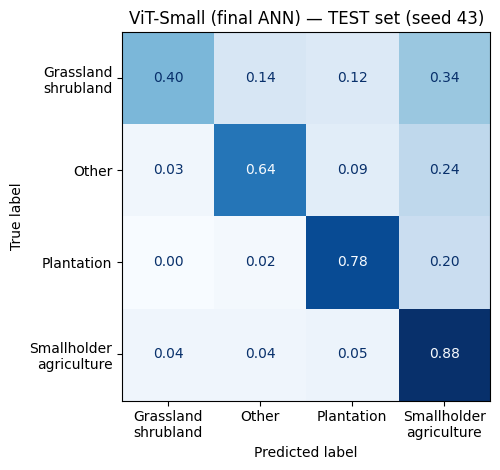

In [ ]:
# Confusion matrix of the final ANN on the test set (app model seed) + the ViT per seed for reference
pred = np.load(OUT7 / f"test_pred_vit_small_final_s{s_app}.npy")
cm = confusion_matrix(Y_TE, pred, labels=range(len(CLASSES)), normalize="true")
ConfusionMatrixDisplay(cm, display_labels=[c.replace(" ", "\n") for c in CLASSES]).plot(cmap="Blues", values_format=".2f", colorbar=False)
plt.title(f"ViT-Small (final ANN) — TEST set (seed {s_app})"); plt.tight_layout(); plt.savefig(OUT7 / "confusion_vit_test.png", dpi=150); plt.show()

In [ ]:
# Validation vs test macro-F1 (did validation results hold up?)
val_ref = {"ViT-Small (final ANN)": [json.load(open(RUNS3 / f"S3-VIT-FINAL-s{s}" / "result.json"))["val"]["macro_f1"] for s in SEEDS]}
te = json.load(open(OUT7 / "vit_small_final.json"))["per_seed"]
print(f"ViT macro-F1  validation {np.mean(val_ref['ViT-Small (final ANN)']):.3f} → test {np.mean([m['macro_f1'] for m in te]):.3f}")

ViT macro-F1  validation 0.760 → test 0.696


## Part 7 : Submission helpers
Creates `forestnet_project/submission/` with: a **dataset download script**, a **small data sample**
(20 training events, one composite each — the full dataset is 3.36 GB, above the 500 MB limit), and
`requirements.txt` with the exact library versions of this environment.

In [ ]:
#thogh planned to use not using as data set anyways can be downloaded in stage 01
SUB = BASE / "submission"; SUB.mkdir(exist_ok=True)
(SUB / "download_data.py").write_text(f'''"""Download the ForestNet dataset (CC BY 4.0, Irvin et al., 2020) and verify it is the exact file used."""
import hashlib, urllib.request, zipfile, sys
from pathlib import Path
URL = "{meta['dataset_url']}"
SHA256 = "{meta['zip_sha256']}"
out = Path(sys.argv[1] if len(sys.argv) > 1 else "forestnet_project/data") ; out.mkdir(parents=True, exist_ok=True)
z = out / "ForestNetDataset.zip"
if not z.exists():
    print("Downloading (3.4 GB)..."); urllib.request.urlretrieve(URL, z)
h = hashlib.sha256(); f = open(z, "rb")
for b in iter(lambda: f.read(1 << 20), b""): h.update(b)
assert h.hexdigest() == SHA256, "Checksum mismatch: not the same file as used in this project"
print("Checksum OK. Extracting..."); zipfile.ZipFile(z).extractall(out / "raw"); print("Done:", out / "raw")
''')
rng = np.random.default_rng(SEED)
sample_paths = [man.example_path.values[i] for c in CLASSES for i in rng.choice(TR_IDX[man.y.values[TR_IDX] == CLS2ID[c]], min(5, int((man.y.values[TR_IDX] == CLS2ID[c]).sum())), replace=False)]
with zipfile.ZipFile(SUB / "forestnet_sample_20_train_events.zip", "w", zipfile.ZIP_DEFLATED) as zout:
    for p in sample_paths:
        zout.writestr(f"{p}/images/visible/composite.png", ZF.read(f"{PREFIX}{p}/images/visible/composite.png"))
        try:
            zout.writestr(f"{p}/forest_loss_region.pkl", ZF.read(f"{PREFIX}{p}/forest_loss_region.pkl"))
        except KeyError:
            pass
    zout.writestr("sample_labels.csv", man[man.example_path.isin(sample_paths)][["example_path", "split", "merged_label", "label", "latitude", "longitude", "year"]].to_csv(index=False))
import importlib.metadata as md
pkgs = ["torch", "torchvision", "timm", "numpy", "pandas", "scikit-learn", "xgboost", "scikit-image", "scipy", "matplotlib",
        "pillow", "gradio", "terratorch", "google-genai", "imagehash", "shapely", "joblib"]
req = []
for p in pkgs:
    try: req.append(f"{p}=={md.version(p)}")
    except md.PackageNotFoundError: req.append(f"{p}  # not installed in this session")
(SUB / "requirements.txt").write_text("\n".join(req) + "\n")
print("Submission helpers written to", SUB); print(open(SUB / "requirements.txt").read())
print(f"Sample zip: {(SUB / 'forestnet_sample_20_train_events.zip').stat().st_size / 1e6:.1f} MB")

Submission helpers written to /content/drive/MyDrive/forestnet_project/submission
torch==2.11.0+cpu
torchvision==0.26.0+cpu
timm==1.0.30
numpy==2.2.6
pandas==2.2.3
scikit-learn==1.6.1
xgboost==3.4.1
scikit-image==0.25.2
scipy==1.16.3
matplotlib==3.10.0
pillow==11.3.0
gradio==6.31.0
terratorch==1.2.14
google-genai==2.12.1
imagehash  # not installed in this session
shapely==2.2.0
joblib==1.6.0

Sample zip: 2.7 MB
